# 1. Data Aquisition

In [24]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import matplotlib.pyplot as plt

In [26]:


from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import MinMaxScaler


from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay


from sklearn.ensemble import RandomForestClassifier




pd.set_option('display.float', '{:.2f}'.format)
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 50)

In [27]:
'''
import pandas as pd

df = pd.read_csv("/content/drive/Othercomputers/My Computer/project/python/accepted_2007_to_2018Q4.csv", low_memory=False)
df.head()
'''


'\nimport pandas as pd\n\ndf = pd.read_csv("/content/drive/Othercomputers/My Computer/project/python/accepted_2007_to_2018Q4.csv", low_memory=False)\ndf.head()\n'

In [28]:
'''
import pandas as pd
#df = pd.read_csv("/content/drive/Othercomputers/My Computer/project/python/accepted_2007_to_2018Q4.csv", low_memory=False)
df['issue_d'] = pd.to_datetime(df['issue_d'])
for year in [2017, 2016, 2015, 2014]:
    df_year = df[df['issue_d'].dt.year == year].copy()
    df_year.to_csv(f"/content/drive/MyDrive/python/df_{year}.csv", index=False)
'''

'\nimport pandas as pd\n#df = pd.read_csv("/content/drive/Othercomputers/My Computer/project/python/accepted_2007_to_2018Q4.csv", low_memory=False)\ndf[\'issue_d\'] = pd.to_datetime(df[\'issue_d\'])\nfor year in [2017, 2016, 2015, 2014]:\n    df_year = df[df[\'issue_d\'].dt.year == year].copy()\n    df_year.to_csv(f"/content/drive/MyDrive/python/df_{year}.csv", index=False)\n'

In [29]:
'''
import pandas as pd
# convert issue date to datetime
df['issue_d'] = pd.to_datetime(df['issue_d'])

# filter rows based on issue year
df_2018 = df[df['issue_d'].dt.year == 2018].copy()

df_2018.head()
'''

"\nimport pandas as pd\n# convert issue date to datetime\ndf['issue_d'] = pd.to_datetime(df['issue_d'])\n\n# filter rows based on issue year\ndf_2018 = df[df['issue_d'].dt.year == 2018].copy()\n\ndf_2018.head()\n"

In [30]:
df = pd.read_csv("/content/drive/MyDrive/python/df_2014.csv", low_memory=False)
df.head()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,...,sec_app_collections_12_mths_ex_med,sec_app_mths_since_last_major_derog,hardship_flag,hardship_type,hardship_reason,hardship_status,deferral_term,hardship_amount,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_length,hardship_dpd,hardship_loan_status,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,36805548,NaN,10400.00,10400.00,10400.00,36 months,6.99,321.08,A,A3,Truck Driver Delivery Personel,8 years,MORTGAGE,58000.00,Not Verified,2014-12-01,Charged Off,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,credit_card,Credit card refinancing,937xx,CA,14.92,...,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,38098114,NaN,15000.00,15000.00,15000.00,60 months,12.39,336.64,C,C1,MANAGEMENT,10+ years,RENT,78000.00,Source Verified,2014-12-01,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,Debt consolidation,235xx,VA,12.03,...,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2,37822187,NaN,9600.00,9600.00,9600.00,36 months,13.66,326.53,C,C3,Admin Specialist,10+ years,RENT,69000.00,Source Verified,2014-12-01,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,Debt consolidation,077xx,NJ,25.81,...,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
3,37662224,NaN,7650.00,7650.00,7650.00,36 months,13.66,260.20,C,C3,Technical Specialist,< 1 year,RENT,50000.00,Source Verified,2014-12-01,Charged Off,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,Debt consolidation,850xx,AZ,34.81,...,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
4,37612354,NaN,12800.00,12800.00,12800.00,60 months,17.14,319.08,D,D4,Senior Sales Professional,10+ years,MORTGAGE,125000.00,Verified,2014-12-01,Current,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,car,Car financing,953xx,CA,8.31,...,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN


In [31]:
df.shape

(235629, 151)

In [32]:
# Get only categorical columns with more than 7 unique values
cat_cols = df.select_dtypes(include=['object', 'category']).columns
cols_to_drop = [col for col in cat_cols if df[col].nunique() > 7]

# Drop them
df.drop(columns=cols_to_drop, inplace=True)

In [33]:
df.shape

(235629, 132)

In [34]:
# Define the mapping
loan_status_mapping = {
    'Fully Paid': 1,
    'Current': 1,
    'In Grace Period': 1,
    'Late (16-30 days)': 0,
    'Late (31-120 days)': 0,
    'Charged Off': 0,
    'Default': 0
}

# Apply the mapping to the 'Loan_Status' column
df['loan_status_binary'] = df['loan_status'].map(loan_status_mapping)
df.drop('loan_status', axis=1, inplace=True)

df['loan_status_binary'].value_counts()
df.rename(columns={'loan_status_binary': 'loan_status'}, inplace=True)

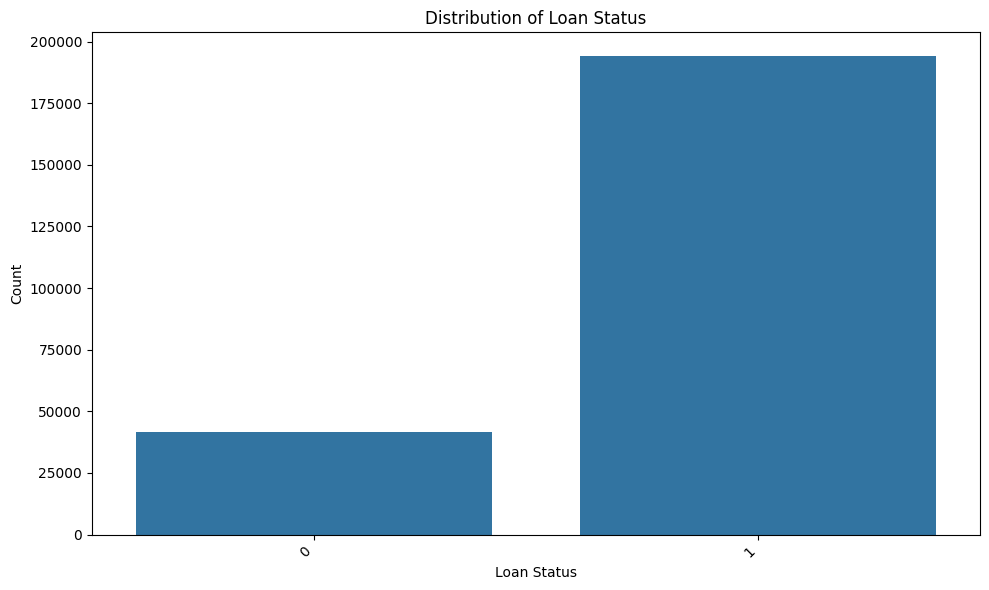

In [35]:
# Get the value counts of the 'loan_status' column
loan_status_counts = df['loan_status'].value_counts()

# Create the bar plot
plt.figure(figsize=(10, 6))
sns.barplot(x=loan_status_counts.index, y=loan_status_counts.values)
plt.title('Distribution of Loan Status')
plt.xlabel('Loan Status')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right') # Rotate x-axis labels for better readability
plt.tight_layout() # Adjust layout to prevent labels overlapping
plt.show()

In [36]:
# Identify categorical columns to convert, excluding the target 'loan_status'
cat_cols_to_dummy = [col for col in df.select_dtypes(include=['object', 'category']).columns if col != 'loan_status']

# Convert to dummy variables
df = pd.get_dummies(df, columns=cat_cols_to_dummy, drop_first=True)

# Check the new shape of your dataset
print(df.shape)

(235629, 141)


In [37]:

# 1. Drop columns that are mostly empty (e.g., more than 30% missing values)
threshold = len(df) * 0.7
df.dropna(thresh=threshold, axis=1, inplace=True)

# 2. Now you can safely drop remaining rows with missing values
df.dropna(inplace=True)

print(df.shape)


(198507, 95)


In [38]:
df.fillna(df.median(numeric_only=True), inplace=True)

In [39]:
df.shape


(198507, 95)

#8. Removing Outliers

In [40]:
train, test = train_test_split(df, test_size=0.20, random_state=42)

print(train.shape)
print(test.shape)

(158805, 95)
(39702, 95)


In [41]:
print("Original shape:", train.shape)

# Dynamically select all continuous numerical columns (excluding binary 0/1 columns and the target column)
numerical_cols = train.select_dtypes(include=[np.number]).columns.tolist()
features = [
    col for col in numerical_cols
    if col != 'loan_status' and not set(train[col].dropna().unique()).issubset({0, 1, 0.0, 1.0})
]

print(f"Analyzing {len(features)} continuous numerical columns: {features}\n")


# Filter outliers using the IQR (box plot) method and track outlier counts
for col in features:
    Q1 = train[col].quantile(0.25)
    Q3 = train[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR


    # Filter outliers
    train = train[(train[col] >= lower_bound) & (train[col] <= upper_bound)]

print("Shape after IQR outlier removal on all numerical columns:", train.shape)

Original shape: (158805, 95)
Analyzing 69 continuous numerical columns: ['id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'int_rate', 'installment', 'annual_inc', 'dti', 'delinq_2yrs', 'fico_range_low', 'fico_range_high', 'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_amnt', 'last_fico_range_high', 'last_fico_range_low', 'collections_12_mths_ex_med', 'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'total_rev_hi_lim', 'acc_open_past_24mths', 'avg_cur_bal', 'bc_open_to_buy', 'bc_util', 'chargeoff_within_12_mths', 'delinq_amnt', 'mo_sin_old_il_acct', 'mo_sin_old_rev_tl_op', 'mo_sin_rcnt_rev_tl_op', 'mo_sin_rcnt_tl', 'mort_acc', 'mths_since_recent_bc', 'mths_since_recent_inq', 'num_accts_ever_120_pd', 'num_actv_bc_tl', 'num_actv_rev_tl', 'num_bc_sats', 'num_bc_tl', 'num_il_tl', '

In [42]:
X_train, y_train = train.drop('loan_status', axis=1), train.loan_status
X_test, y_test = test.drop('loan_status', axis=1), test.loan_status

In [43]:
scaler = MinMaxScaler(feature_range=(0, 1))
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [44]:
pip install catboost

Training : KNN


/tmp/ipykernel_12677/3203949141.py:57: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  comparison_table = pd.concat([comparison_table, new_row], ignore_index=True)


Model: KNN
              precision    recall  f1-score   support

           0       0.95      0.15      0.26      7203
           1       0.84      1.00      0.91     32499

    accuracy                           0.84     39702
   macro avg       0.89      0.57      0.59     39702
weighted avg       0.86      0.84      0.79     39702

Training : Decision Tree
Model: Decision Tree
              precision    recall  f1-score   support

           0       0.73      0.85      0.78      7203
           1       0.97      0.93      0.95     32499

    accuracy                           0.92     39702
   macro avg       0.85      0.89      0.87     39702
weighted avg       0.92      0.92      0.92     39702

Training : Random Forest
Model: Random Forest
              precision    recall  f1-score   support

           0       1.00      0.77      0.87      7203
           1       0.95      1.00      0.97     32499

    accuracy                           0.96     39702
   macro avg       0.97  

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Model: LGBM
              precision    recall  f1-score   support

           0       0.98      0.87      0.92      7203
           1       0.97      1.00      0.98     32499

    accuracy                           0.97     39702
   macro avg       0.98      0.93      0.95     39702
weighted avg       0.97      0.97      0.97     39702

Training : Naive Bayes
Model: Naive Bayes
              precision    recall  f1-score   support

           0       0.73      0.72      0.72      7203
           1       0.94      0.94      0.94     32499

    accuracy                           0.90     39702
   macro avg       0.83      0.83      0.83     39702
weighted avg       0.90      0.90      0.90     39702

Training : Voting Classifier


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Model: Voting Classifier
              precision    recall  f1-score   support

           0       0.99      0.86      0.92      7203
           1       0.97      1.00      0.98     32499

    accuracy                           0.97     39702
   macro avg       0.98      0.93      0.95     39702
weighted avg       0.97      0.97      0.97     39702

Training : Logistic Regression
Model: Logistic Regression
              precision    recall  f1-score   support

           0       0.97      0.87      0.92      7203
           1       0.97      0.99      0.98     32499

    accuracy                           0.97     39702
   macro avg       0.97      0.93      0.95     39702
weighted avg       0.97      0.97      0.97     39702



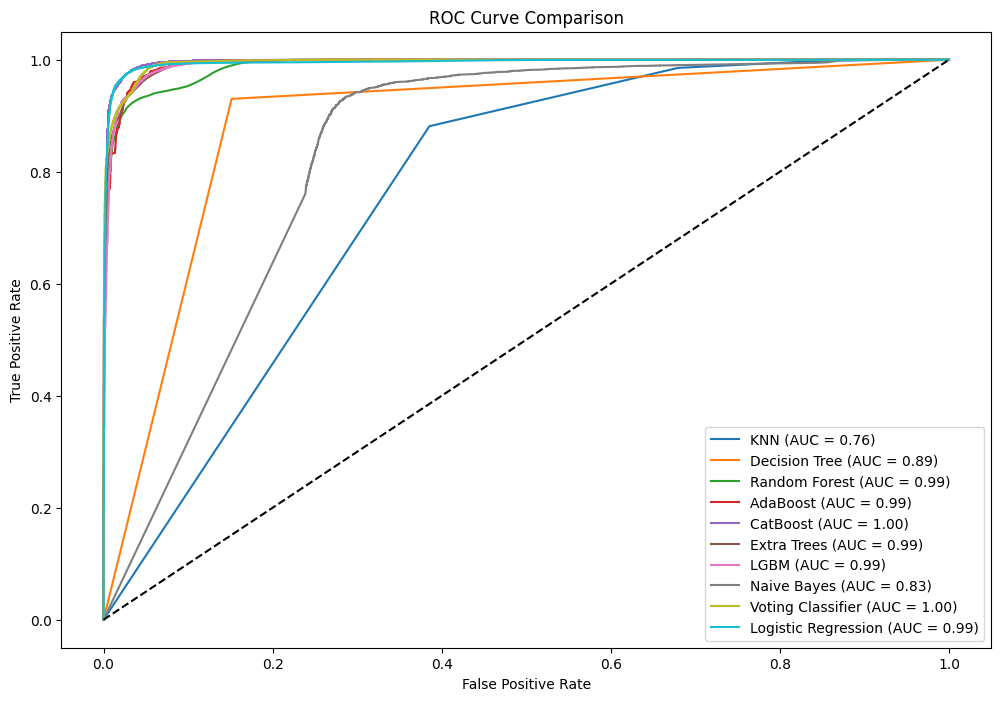


Comparison Table:
                 Model  Accuracy  AUC
4             CatBoost      0.98 1.00
6                 LGBM      0.97 0.99
8    Voting Classifier      0.97 1.00
9  Logistic Regression      0.97 0.99
3             AdaBoost      0.96 0.99
2        Random Forest      0.96 0.99
5          Extra Trees      0.94 0.99
1        Decision Tree      0.92 0.89
7          Naive Bayes      0.90 0.83
0                  KNN      0.84 0.76


In [45]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, ExtraTreesClassifier, VotingClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, roc_curve, auc
import warnings



# List of models
models = {
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(),
    "AdaBoost": AdaBoostClassifier(),
    "CatBoost": CatBoostClassifier(verbose=0), # Suppress CatBoost outputs
    "Extra Trees": ExtraTreesClassifier(),
    'LGBM': LGBMClassifier(verbose=-1), # Suppress LightGBM warnings
    "Naive Bayes": GaussianNB(),
    "Voting Classifier": VotingClassifier(estimators=[
        ('rf', RandomForestClassifier()),
        ('lgbm', LGBMClassifier()),
        ('ada', AdaBoostClassifier())
    ], voting='soft'),
    "Logistic Regression": LogisticRegression(),
   # "Multinomial NB": MultinomialNB()
}

# Dataframe for comparison
comparison_table = pd.DataFrame(columns=["Model", "Accuracy", "AUC"])

# Evaluate and save models
plt.figure(figsize=(12, 8))
for model_name, model in models.items():
    print(f"Training : {model_name}")
    # Train the model
    model.fit(X_train, y_train)

    # Predict and calculate metrics
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else None
    accuracy = accuracy_score(y_test, y_pred)

    # ROC Curve and AUC
    if y_prob is not None:
        fpr, tpr, _ = roc_curve(y_test, y_prob)
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f"{model_name} (AUC = {roc_auc:.2f})")
    else:
        roc_auc = None

    # Add to comparison table
    new_row = pd.DataFrame([{"Model": model_name, "Accuracy": accuracy, "AUC": roc_auc}])
    comparison_table = pd.concat([comparison_table, new_row], ignore_index=True)

    # Print classification report
    print(f"Model: {model_name}")
    print(classification_report(y_test, y_pred))


# Finalize ROC Curve
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

# Display comparison table
print("\nComparison Table:")
print(comparison_table.sort_values(by="Accuracy", ascending=False))


Evaluating: KNN
Evaluating: Decision Tree
Evaluating: Random Forest
Evaluating: AdaBoost
Evaluating: CatBoost
Evaluating: Extra Trees
Evaluating: LGBM


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Evaluating: Naive Bayes
Evaluating: Voting Classifier


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Evaluating: Logistic Regression

Model Evaluation Table:
                 Model  Accuracy  Precision  Recall  F1-Score
4             CatBoost      0.98       0.98    1.00      0.99
6                 LGBM      0.97       0.97    1.00      0.98
8    Voting Classifier      0.97       0.97    1.00      0.98
9  Logistic Regression      0.97       0.97    0.99      0.98
3             AdaBoost      0.96       0.96    1.00      0.98
2        Random Forest      0.96       0.95    1.00      0.98
5          Extra Trees      0.94       0.93    1.00      0.96
1        Decision Tree      0.91       0.97    0.93      0.95
7          Naive Bayes      0.90       0.94    0.94      0.94
0                  KNN      0.84       0.84    1.00      0.91


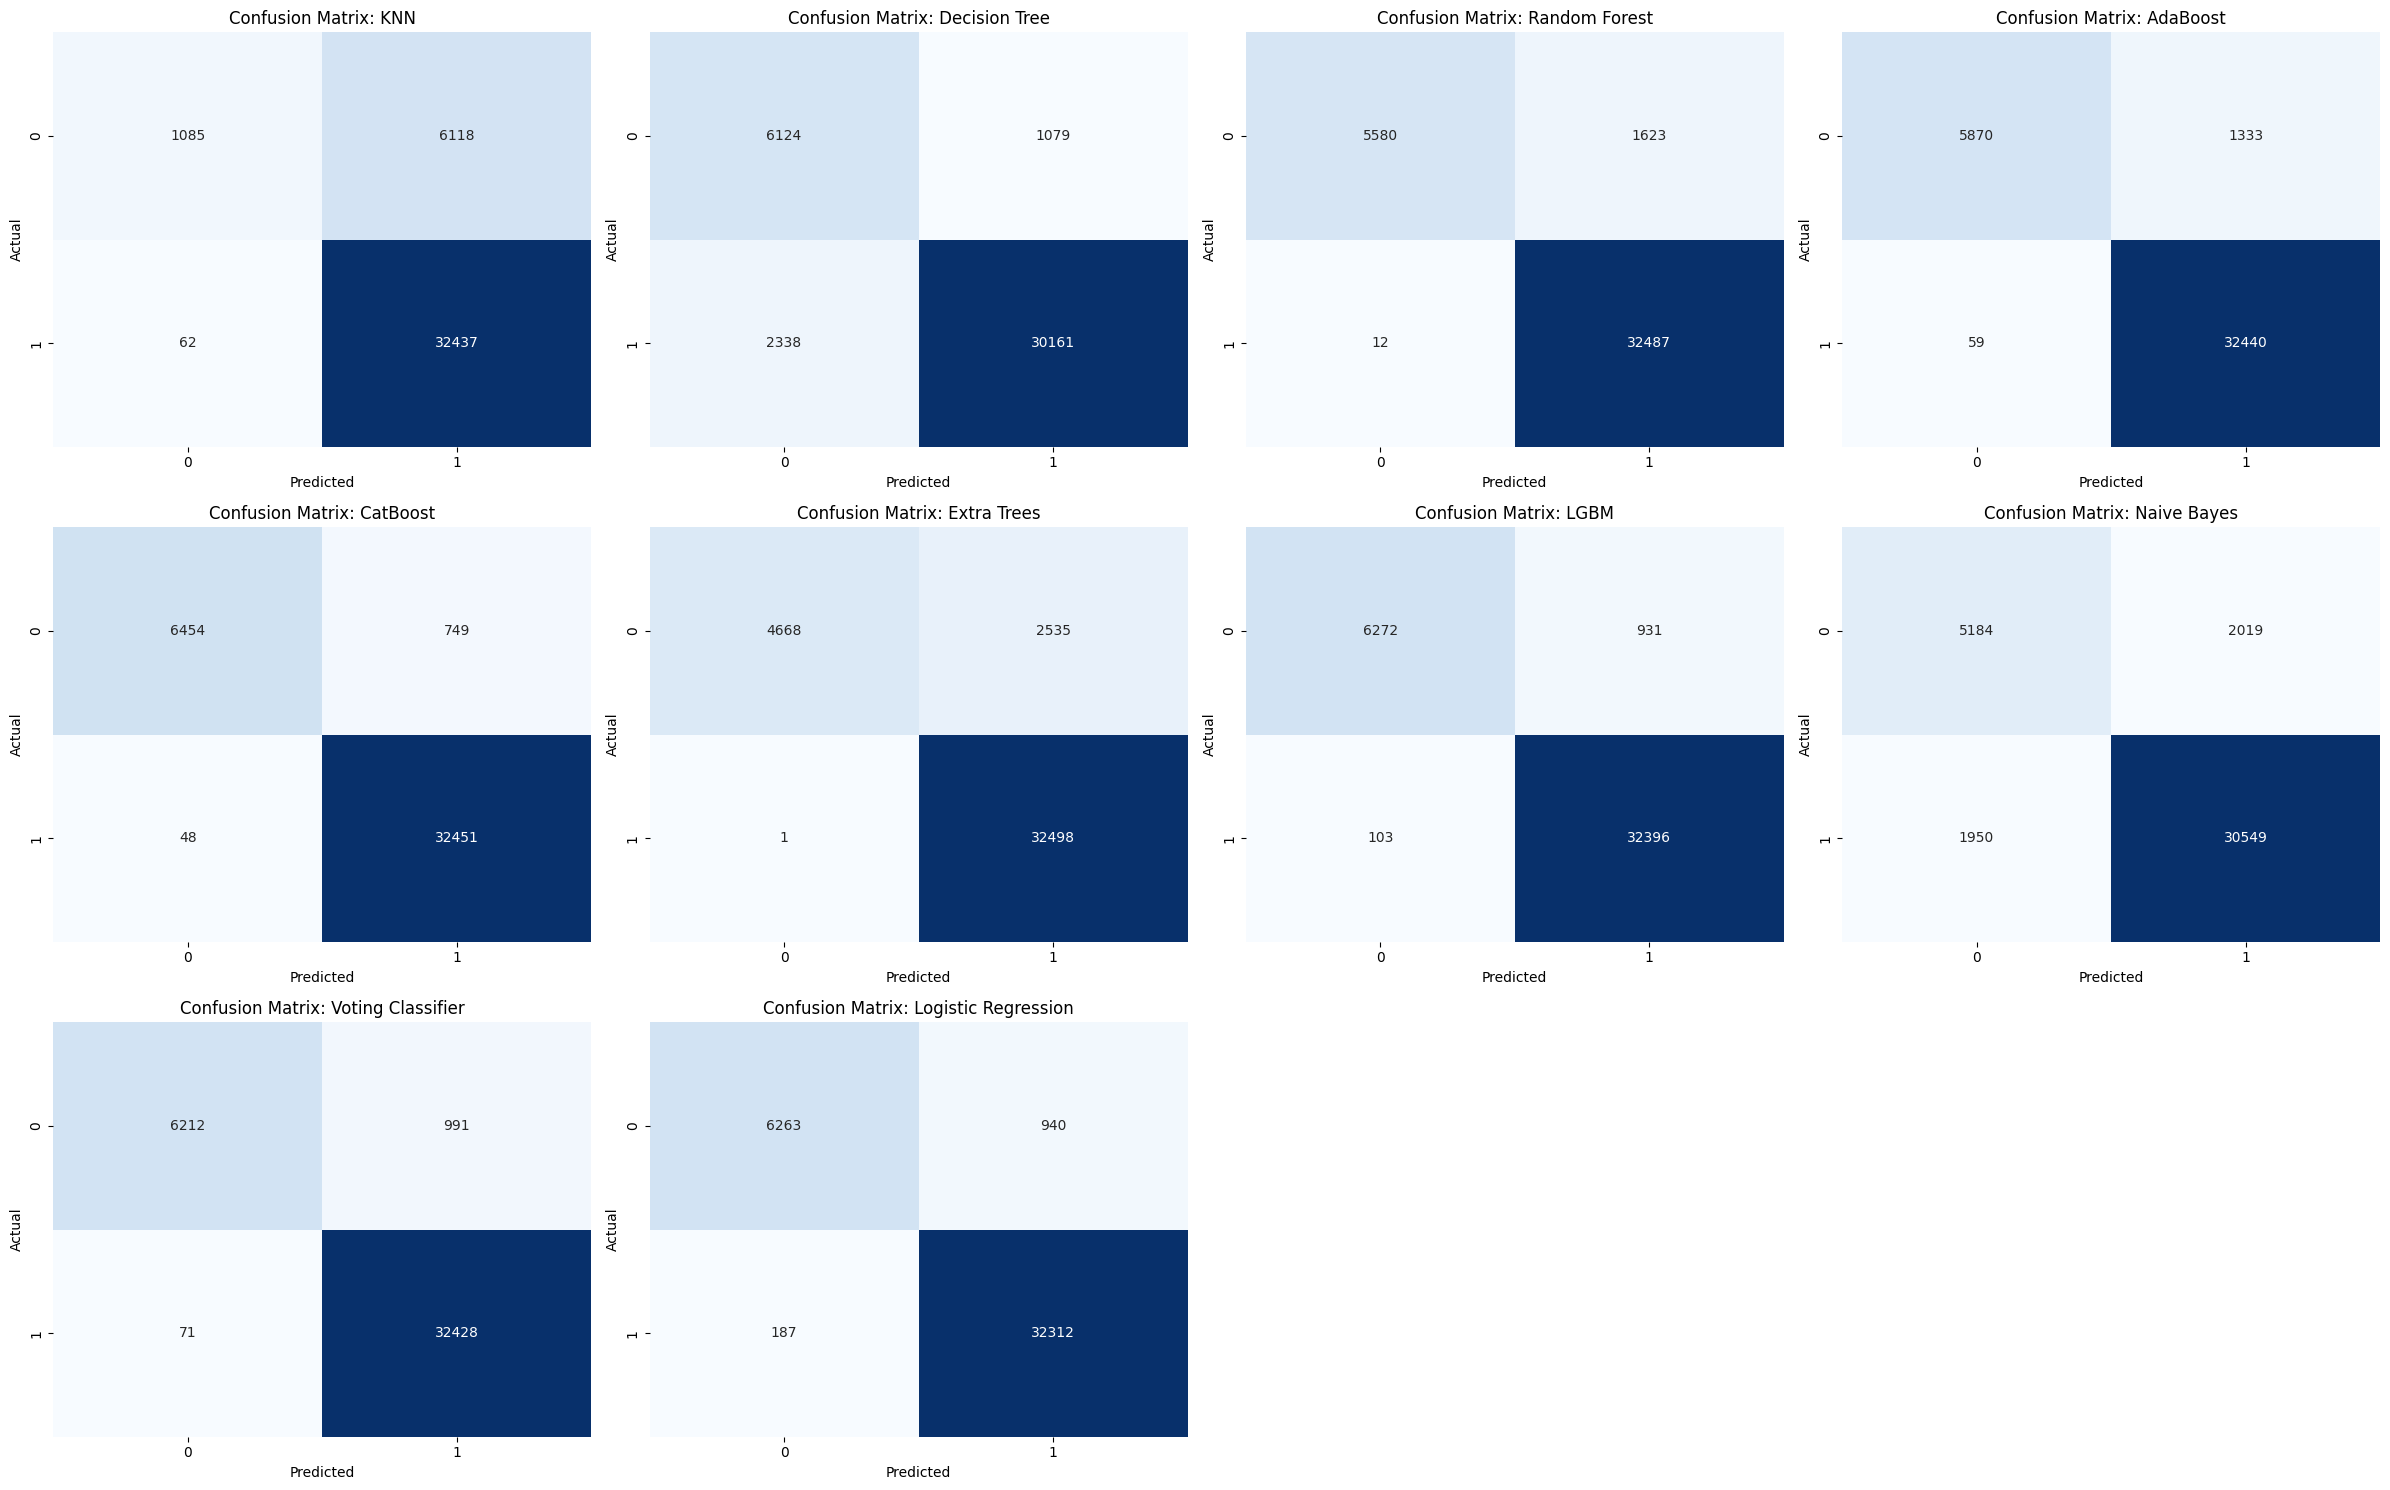

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# Dictionary to store classification reports and confusion matrices
classification_reports = {}
confusion_matrices = {}

# Evaluate and store reports and confusion matrices
for model_name, model in models.items():
    print(f"Evaluating: {model_name}")
    y_pred = model.predict(X_test)

    # Classification report
    report = classification_report(y_test, y_pred, output_dict=True)
    classification_reports[model_name] = report

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    confusion_matrices[model_name] = cm

# Create evaluation table
results_list = []

for model_name, report in classification_reports.items():
    metrics = report['1']  # positive class
    accuracy = report['accuracy']

    results_list.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": metrics['precision'],
        "Recall": metrics['recall'],
        "F1-Score": metrics['f1-score']
    })

evaluation_table = pd.DataFrame(results_list)

# Print evaluation table
print("\nModel Evaluation Table:")
print(evaluation_table.sort_values(by="F1-Score", ascending=False))

# Plot confusion matrices in a single figure
num_models = len(confusion_matrices)
cols = 4
rows = (num_models + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 5 * rows))
axes = axes.flatten()

for i, (model_name, cm) in enumerate(confusion_matrices.items()):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[i], cbar=False)
    axes[i].set_title(f"Confusion Matrix: {model_name}")
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig("plot1.png", transparent=True, dpi=300)
plt.show()


In [24]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier

# Define models and their respective parameter grids
models_to_tune = {
    "Decision Tree": {
        "model": DecisionTreeClassifier(random_state=42),
        "params": {
            "max_depth": [None, 5, 10, 20],
            "min_samples_split": [2, 5, 10],
            "criterion": ["gini", "entropy"]
        }
    },
    "Random Forest": {
        "model": RandomForestClassifier(random_state=42),
        "params": {
            "n_estimators": [50, 100, 150],
            "max_depth": [None, 10, 20],
            "min_samples_split": [2, 5, 10]
        }
    },
    "AdaBoost": {
        "model": AdaBoostClassifier(random_state=42),
        "params": {
            "n_estimators": [50, 100, 150],
            "learning_rate": [0.01, 0.1, 1.0]
        }
    },
    "LGBM": {
        "model": LGBMClassifier(random_state=42, verbose=-1),
        "params": {
            "n_estimators": [50, 100, 150],
            "learning_rate": [0.01, 0.1, 0.2],
            "num_leaves": [15, 31, 50]
        }
    },
    "Logistic Regression": {
        "model": LogisticRegression(max_iter=1000, random_state=42),
        "params": {
            "C": [0.01, 0.1, 1.0, 10.0],
            "solver": ["lbfgs", "liblinear"]
        }
    }
}

best_models = {}

# Perform Randomized Search for each model
for name, config in models_to_tune.items():
    print(f"Optimizing {name}...")
    search = RandomizedSearchCV(
        estimator=config["model"],
        param_distributions=config["params"],
        n_iter=5,
        scoring="f1",
        cv=3,
        random_state=42,
        n_jobs=-1,
        verbose=0
    )
    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    print(f"Best F1-Score for {name}: {search.best_score_:.4f}")
    print(f"Best Parameters: {search.best_params_}\n")


Optimizing Decision Tree...
Best F1-Score for Decision Tree: 0.9962
Best Parameters: {'min_samples_split': 10, 'max_depth': 10, 'criterion': 'gini'}

Optimizing Random Forest...
Best F1-Score for Random Forest: 0.9952
Best Parameters: {'n_estimators': 50, 'min_samples_split': 2, 'max_depth': None}

Optimizing AdaBoost...
Best F1-Score for AdaBoost: 0.9977
Best Parameters: {'n_estimators': 150, 'learning_rate': 1.0}

Optimizing LGBM...
Best F1-Score for LGBM: 0.9987
Best Parameters: {'num_leaves': 15, 'n_estimators': 100, 'learning_rate': 0.2}

Optimizing Logistic Regression...
Best F1-Score for Logistic Regression: 0.9977
Best Parameters: {'solver': 'liblinear', 'C': 10.0}



In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA

# 1. Clean the original train/test features to get rid of NaNs without imputation
X_train_df = pd.DataFrame(X_train)
X_test_df = pd.DataFrame(X_test)

# Identify columns with any NaNs in train or test
nan_cols = list(set(X_train_df.columns[X_train_df.isnull().any()].tolist() +
                    X_test_df.columns[X_test_df.isnull().any()].tolist()))

print(f"Dropping {len(nan_cols)} columns containing NaNs.")

X_train_clean = X_train_df.drop(columns=nan_cols)
X_test_clean = X_test_df.drop(columns=nan_cols)

# 2. Re-scale the cleaned features
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train_clean)
X_test_scaled = scaler.transform(X_test_clean)

# 3. Apply PCA preserving 95% of the explained variance
pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# 4. Update the variables
X_train = X_train_pca
X_test = X_test_pca

print("Original feature count (after dropping NaNs):", X_train_scaled.shape[1])
print("PCA reduced feature count:", X_train.shape[1])
print("Total explained variance:", f"{sum(pca.explained_variance_ratio_):.2%}")

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA

# 1. Re-split from 'train' and 'test' DataFrames to get clean starting points
X_train = train.drop('loan_status', axis=1, errors='ignore')
y_train = train['loan_status']

X_test = test.drop('loan_status', axis=1, errors='ignore')
y_test = test['loan_status']

# 2. Identify and drop columns that contain any NaN values in either dataset
nan_cols_train = X_train.columns[X_train.isnull().any()].tolist()
nan_cols_test = X_test.columns[X_test.isnull().any()].tolist()
all_nan_cols = list(set(nan_cols_train + nan_cols_test))

print(f"Dropping {len(all_nan_cols)} columns containing NaNs: {all_nan_cols}")
X_train = X_train.drop(columns=all_nan_cols)
X_test = X_test.drop(columns=all_nan_cols)

# 3. Apply MinMaxScaler to the clean features
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Apply PCA (preserving 95% of explained variance)
pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# Overwrite variables for modeling
X_train = X_train_pca
X_test = X_test_pca

print("Original feature count (after dropping NaNs):", X_train_scaled.shape[1])
print("PCA reduced feature count:", X_train.shape[1])
print("Total explained variance:", f"{sum(pca.explained_variance_ratio_):.2%}")

In [ ]:
# # @title
# # List of selected columns
# selected_columns = [
#     'loan_amnt', 'term', 'int_rate', 'installment',  'sub_grade',
#     'emp_title', 'emp_length', 'home_ownership', 'annual_inc',
#     'verification_status',  'loan_status', 'purpose', 'title',
#     'dti',  'open_acc', 'pub_rec', 'revol_bal',
#     'revol_util', 'total_acc', 'initial_list_status', 'application_type',
#     'mort_acc', 'pub_rec_bankruptcies'
# ]

# # Create a new DataFrame with only the selected columns
# df = df[selected_columns]


In [ ]:
# df.isnull().sum()

# 2. Data Cleaning

In [ ]:
# # Drop rows with any missing values
# df.dropna(inplace=True)

# # Verify that there are no more missing values
# print("\nMissing values after dropping rows:")
# print(df.isnull().sum())

# # Display the first few rows of the cleaned DataFrame
# print("\nDataFrame after dropping rows with missing values:")

In [ ]:
# 1. Drop columns that are mostly empty (e.g., more than 30% missing values)
threshold = len(df) * 0.7
df.dropna(thresh=threshold, axis=1, inplace=True)

# 2. Now you can safely drop remaining rows with missing values
df.dropna(inplace=True)

print(df.shape)

In [ ]:

pd.options.display.float_format = '{:.2f}'.format
df.describe().T

In [ ]:
# Separate the features and target variable from df_scaled
X = df_scaled.drop('loan_status', axis=1, errors='ignore')
y = df_scaled['loan_status']

# Perform an 80:20 train-test split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

KeyError: 'loan_status'

In [ ]:
# Drop the ID columns from your dataframe
df_scaled.drop(columns=['id', 'member_id'], inplace=True, errors='ignore')

## 3. Identifying the target (y)

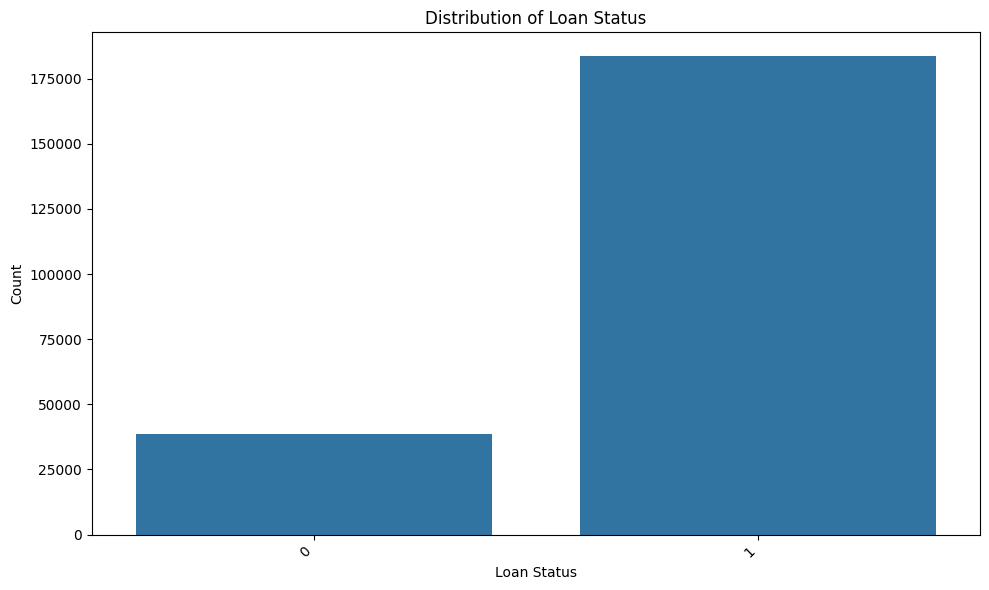

In [ ]:
# Get the value counts of the 'loan_status' column
loan_status_counts = df['loan_status'].value_counts()

# Create the bar plot
plt.figure(figsize=(10, 6))
sns.barplot(x=loan_status_counts.index, y=loan_status_counts.values)
plt.title('Distribution of Loan Status')
plt.xlabel('Loan Status')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right') # Rotate x-axis labels for better readability
plt.tight_layout() # Adjust layout to prevent labels overlapping
plt.show()

### Here we can see this dataset is imbalance we have addressed this issue later.

# 4. Correlation Analysis

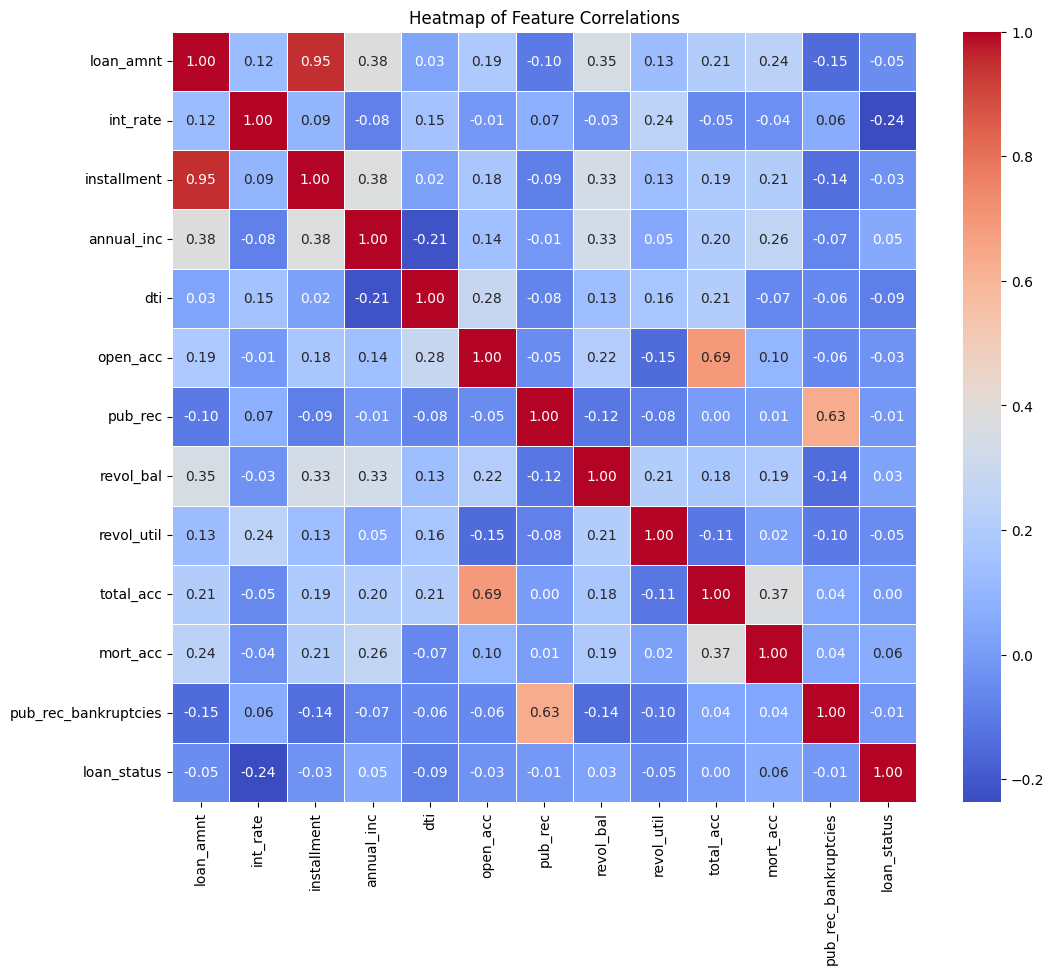

In [ ]:
# Select only numerical columns for correlation analysis
numerical_df = df.select_dtypes(include=np.number)

# Calculate the correlation matrix
correlation_matrix = numerical_df.corr()

# Generate a heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Heatmap of Feature Correlations')
plt.show()

#5. removing unnecessary columns

In [ ]:
df.emp_title.nunique()

75306

### there are too many unique job titles to try to convert this to a dummy variable feature. Let's remove that emp_title column.

In [ ]:
df.drop('emp_title', axis=1, inplace=True)

In [ ]:
for year in df.emp_length.unique():
    print(f"{year} years in this position:")
    print(f"{df[df.emp_length == year].loan_status.value_counts(normalize=True)}")
    print('==========================================')

8 years years in this position:
loan_status
1   0.82
0   0.18
Name: proportion, dtype: float64
10+ years years in this position:
loan_status
1   0.83
0   0.17
Name: proportion, dtype: float64
< 1 year years in this position:
loan_status
1   0.81
0   0.19
Name: proportion, dtype: float64
6 years years in this position:
loan_status
1   0.82
0   0.18
Name: proportion, dtype: float64
2 years years in this position:
loan_status
1   0.83
0   0.17
Name: proportion, dtype: float64
7 years years in this position:
loan_status
1   0.82
0   0.18
Name: proportion, dtype: float64
9 years years in this position:
loan_status
1   0.82
0   0.18
Name: proportion, dtype: float64
3 years years in this position:
loan_status
1   0.83
0   0.17
Name: proportion, dtype: float64
4 years years in this position:
loan_status
1   0.83
0   0.17
Name: proportion, dtype: float64
5 years years in this position:
loan_status
1   0.83
0   0.17
Name: proportion, dtype: float64
1 year years in this position:
loan_status
1   

### Charge off rates are extremely similar across all employment lengths. So we are going to drop the emp_length column.

In [ ]:
df.drop('emp_length', axis=1, inplace=True)

In [ ]:
df.title.value_counts().head()

,count
title,
Debt consolidation,133323
Credit card refinancing,51058
Home improvement,11923
Other,9516
Major purchase,3590


In [ ]:
df.purpose.value_counts().head()

,count
purpose,
debt_consolidation,135548
credit_card,52138
home_improvement,12066
other,9642
major_purchase,3627


### The title column is simply a string subcategory/description of the purpose column. So we are going to drop the title column.

In [ ]:
df.drop('title', axis=1, inplace=True)

In [ ]:
df1=df

# 6. Encoding

In [ ]:
print([column for column in df.columns if df[column].dtype == object])

['term', 'sub_grade', 'home_ownership', 'verification_status', 'purpose', 'initial_list_status', 'application_type']


term

In [ ]:
df.term.unique()

array([' 36 months', ' 60 months'], dtype=object)

In [ ]:
term_values = {' 36 months': 36, ' 60 months': 60}
df['term'] = df.term.map(term_values)

In [ ]:
df.term.unique()

array([36, 60])

sub_grade

In [ ]:
dummies = ['sub_grade', 'verification_status', 'purpose', 'initial_list_status',
           'application_type', 'home_ownership']
df = pd.get_dummies(df, columns=dummies, drop_first=True)

# 7. Test Train Split

# 9. Addressing Imbalance dataset issue

In [ ]:
from imblearn.under_sampling import RandomUnderSampler

# Define the undersampling strategy
undersampler = RandomUnderSampler(sampling_strategy='majority', random_state=42)

# Fit and resample the training data
X_train_undersampled, y_train_undersampled = undersampler.fit_resample(X_train, y_train)

print("Shape of X_train before undersampling:", X_train.shape)
print("Shape of X_train after undersampling:", X_train_undersampled.shape)
print("Value counts of y_train before undersampling:\n", y_train.value_counts())
print("Value counts of y_train after undersampling:\n", y_train_undersampled.value_counts())

Shape of X_train before undersampling: (175792, 65)
Shape of X_train after undersampling: (61494, 65)
Value counts of y_train before undersampling:
 loan_status
1    145045
0     30747
Name: count, dtype: int64
Value counts of y_train after undersampling:
 loan_status
0    30747
1    30747
Name: count, dtype: int64


In [ ]:
X_train = X_train_undersampled
y_train = y_train_undersampled

In [ ]:
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((61494, 65), (61494,), (44439, 65), (44439,))

#10. Normalizing the data

# 10.1 Principal Component Analysis (PCA)


In [ ]:
'''
from sklearn.decomposition import PCA
pca = PCA(.95)

x_train_pca = pca.fit_transform(X_train)
x_test_pca = pca.transform(X_test)
x_train_pca.shape, x_test_pca.shape
'''

'\nfrom sklearn.decomposition import PCA\npca = PCA(.95)\n\nx_train_pca = pca.fit_transform(X_train)\nx_test_pca = pca.transform(X_test)\nx_train_pca.shape, x_test_pca.shape\n'

In [ ]:
'''
X_train = x_train_pca
X_test = x_test_pca
'''

'\nX_train = x_train_pca\nX_test = x_test_pca\n'

# 11. Model Training


# 11. Model Evaluation

In [ ]:
plt.savefig("plot.png", transparent=True, dpi=300)

<Figure size 640x480 with 0 Axes>

In [ ]:
plt.savefig("plot.png", transparent=True, dpi=300)

<Figure size 640x480 with 0 Axes>

In [ ]:
plt.savefig("plot.png", transparent=True, dpi=300)

<Figure size 640x480 with 0 Axes>